# Fountain calling with dataset-specific thresholds

Run from top to bottom. Functions live in `fountain_tools/`; plots take a dataset result explicitly.
The supplied WT mask stays linear O/E and unchanged. Each dataset receives its own expected
contacts, scores, Li prominence threshold, FS 90th percentile, and Scharr 75th percentile.

The original notebook is preserved in `archive/fountains-dc-original.ipynb`.
Downstream CTCF/enhancer work is in `fountains-dc-annotations.ipynb`.

**Required external inputs:** your 41 x 41 mask, mm10 view file, and balanced 25 kb maps.
These were referenced by path rather than attached. The 20 manual anchor bins are bundled.


In [1]:
from pathlib import Path
import logging
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep this notebook beside fountain_tools/. Change PROJECT_ROOT for your data.
MODULE_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(MODULE_ROOT))
PROJECT_ROOT = MODULE_ROOT  # e.g. Path("/home/irzhe/chromatin_DC/scripts")

from fountain_tools import (
    Settings,
    run_dataset, match_manual_peaks, select_examples,
)
from fountain_tools.plots import (
    plot_mask, plot_dense_examples, plot_distributions,
    plot_noise_prominence, plot_fountain_region, compare_counts,
)

logging.getLogger("fontTools").setLevel(logging.WARNING)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "pdf.fonttype": 42, "ps.fonttype": 42})


## 1. Inputs and target datasets

All maps must use the same assembly, resolution, balancing convention, view, and WT scoring mask.
Edit the dataset list to apply the pipeline to another map. Each dataset calculates its own
thresholds from its unfiltered scores. Cache provenance checks protect snippet and score reuse.


In [2]:
COOLER_PATHS = {
    'yang2023_dc_CTCFko': '/net/levsha/share/lab/yang2023_dc/results/hic/coolers_library_group/yang2023_dc_CTCFko.mm10.mapq_30.1000.mcool'}

MASK_PATH = PROJECT_ROOT / "data/WT.coolpuppy.25000.500Kb.mask.npy"
VIEW_PATH = PROJECT_ROOT / "data/mm10.vieframe.tsv"
MANUAL_BED = PROJECT_ROOT / "data/manual_fountains.25kb.bed"
if not MANUAL_BED.exists():
    MANUAL_BED = MODULE_ROOT / "data/manual_fountains.25kb.bed"

OUTPUT_ROOT = PROJECT_ROOT / "results/fountains/maps"
NPROC_EXPECTED = 20

# Start with the original target and one additional map. Edit this list freely.
DATASETS_TO_RUN = ["yang2023_dc_CTCFko"]
ACTIVE_DATASET = DATASETS_TO_RUN[0]


## 2. Scoring settings and threshold calculation

The WT mask is loaded directly; there is no configuration to freeze or calibration table to recover.
For **each dataset**, `run_dataset` calculates the original notebook's Li/percentile cutoffs:

- Prominence: `threshold_li` on finite, nonnegative local-peak prominences.
- FS: 90th percentile of all finite genomic-bin FS values.
- Scharr noise: 75th percentile of all finite genomic-bin Scharr values.

These populations are taken before any peak/quality/calling filters. Calls require **FS > P90**,
**prominence > Li**, and **Scharr < P75**, using strict comparisons. Missing measurements fail calling.
No fixed numerical FS/noise/prominence fallback is used. Each run saves `thresholds.json`.

The existing 0.35 finite-pixel cutoff keeps its full-mask denominator. `coverage` is a separate
upper-triangle diagnostic, so complete triangular snippets display 100%. Example-image density
and spacing filters do not affect calls. Percentile cutoffs select relative scores within each map;
they do not imply the same absolute strength or detection sensitivity between maps.


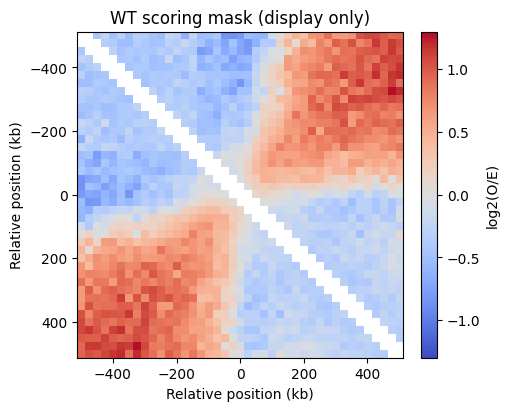

In [3]:
settings = Settings(resolution=25_000, flank=500_000, min_diag=2, assembly="mm10")
FS_PERCENTILE = 90
NOISE_PERCENTILE = 100
MIN_MASK_FRACTION = 0.35
MIN_NONZERO_FRACTION = 0.0

from fountain_tools import load_mask
fig = plot_mask(load_mask(MASK_PATH, settings), settings)
plt.show()


## 3. Score each map and calculate its thresholds

Each map gets its own balanced, unsmoothed expected contacts. Snippets are streamed to disk
in cooler-bin order. FS is Pearson(WT mask, linear O/E); Scharr is calculated from the full linear
snippet. Local prominence is evaluated within contiguous finite FS runs and view regions.

This step may take several minutes and about 1.4 GiB of snippet storage per 109,033-bin map.
Compatible reruns reuse scores/snippets, then fit thresholds from that dataset's scores. Input
changes raise a clear cache error. The new output root preserves the previous pipeline's results.


In [4]:
results = {}
for label in DATASETS_TO_RUN:
    if label not in COOLER_PATHS:
        raise KeyError(f"Add a path for {label!r} to COOLER_PATHS.")
    results[label] = run_dataset(
        label, COOLER_PATHS[label], MASK_PATH, VIEW_PATH, settings,
        output_root=OUTPUT_ROOT, nproc=NPROC_EXPECTED,
        fs_percentile=FS_PERCENTILE, noise_percentile=NOISE_PERCENTILE,
        min_mask_fraction=MIN_MASK_FRACTION, min_nonzero_fraction=MIN_NONZERO_FRACTION,
    )

comparison = compare_counts(results)
display(comparison)
comparison.to_csv(OUTPUT_ROOT / "dataset_comparison.tsv", sep="\t", index=False)

active = results[ACTIVE_DATASET]
print("Active dataset thresholds:", active.thresholds)
display(active.summary)
display(active.calls.groupby("chrom", observed=True).size().rename("n_candidates"))


Calculating expected contacts for /net/levsha/share/lab/yang2023_dc/results/hic/coolers_library_group/yang2023_dc_CTCFko.mm10.mapq_30.1000.mcool::/resolutions/25000


INFO:root:creating a Pool of 20 workers


  chr1: 7,778 complete windows
  chr2: 7,244 complete windows
  chr3: 6,361 complete windows
  chr4: 6,220 complete windows
  chr5: 6,033 complete windows
  chr6: 5,949 complete windows
  chr7: 5,777 complete windows
  chr8: 5,136 complete windows
  chr9: 4,943 complete windows
  chr10: 5,187 complete windows
  chr11: 4,843 complete windows
  chr12: 4,765 complete windows
  chr13: 4,776 complete windows
  chr14: 4,956 complete windows
  chr15: 4,121 complete windows
  chr16: 3,888 complete windows
  chr17: 3,759 complete windows
  chr18: 3,588 complete windows
  chr19: 2,417 complete windows
  chrX: 6,801 complete windows
Calculating FS, pixel coverage, and Scharr noise...
Dataset thresholds: Thresholds(min_fs=0.40452944312749567, min_prominence=0.22064963478937816, max_noise=275.6122960912918, min_mask_fraction=0.35, min_nonzero_fraction=0.0)
               stage  n_candidates
  All local FS peaks         10274
Pixel-quality cutoff          9578
           FS cutoff          1415
   P

,dataset,eligible_scored_bins,n_calls,calls_per_1000_eligible_bins,fs_cutoff,prominence_cutoff,noise_cutoff
0,yang2023_dc_CTCFko,97002,1087,11.205955,0.404529,0.22065,275.612296


Active dataset thresholds: Thresholds(min_fs=0.40452944312749567, min_prominence=0.22064963478937816, max_noise=275.6122960912918, min_mask_fraction=0.35, min_nonzero_fraction=0.0)


,stage,n_candidates
0,All local FS peaks,10274
1,Pixel-quality cutoff,9578
2,FS cutoff,1415
3,Prominence cutoff,1087
4,Noise cutoff,1087


chrom
chr1     84
chr10    57
chr11    61
chr12    52
chr13    56
chr14    40
chr15    42
chr16    36
chr17    38
chr18    38
chr19    27
chr2     80
chr3     54
chr4     67
chr5     68
chr6     65
chr7     61
chr8     62
chr9     66
chrX     33
Name: n_candidates, dtype: int64

## 4. Match manual bases to nearest local peaks

Matching uses a fixed +/-50 kb tolerance, independent of score magnitude and thresholds.
Unmatched annotations remain visible. Multiple annotations can share a peak; plots count that
peak once. These manual sites constructed the WT scoring mask, so they are training examples,
not an independent validation set. They are not used as truth labels for SMC peaks.


In [5]:
manual_matches = match_manual_peaks(
    active.scores, MANUAL_BED,
    resolution=active.settings.resolution, max_distance=50_000,
)
manual_matches.to_csv(active.directory / "manual_peak_matches.tsv", sep="\t", index=False)
display(manual_matches)
print("Matched annotations:", int(manual_matches.matched.sum()), "/", len(manual_matches))


,chrom,manual_start,manual_center,matched,peak_start,peak_end,distance_bp,offset_bp,FS,FS_peaks,Scharr_box,shared_peak
0,chr4,75250000,75262500.0,True,75275000.0,75300000.0,25000.0,25000.0,0.827072,1.233595,41.174748,False
1,chr4,74300000,74312500.0,True,74250000.0,74275000.0,50000.0,-50000.0,0.442907,0.715928,28.240130,False
2,chr4,80275000,80287500.0,True,80250000.0,80275000.0,25000.0,-25000.0,0.622460,0.808795,34.123003,False
3,chr4,84975000,84987500.0,True,84950000.0,84975000.0,25000.0,-25000.0,0.744238,1.066943,28.362553,False
4,chr4,93450000,93462500.0,True,93450000.0,93475000.0,0.0,0.0,0.828615,1.463788,62.363305,False
5,chr4,97775000,97787500.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
6,chr5,12925000,12937500.0,True,12900000.0,12925000.0,25000.0,-25000.0,0.727720,0.989949,43.261840,False
7,chr5,17925000,17937500.0,True,17900000.0,17925000.0,25000.0,-25000.0,0.796083,1.136862,43.047982,False
8,chr5,27150000,27162500.0,True,27150000.0,27175000.0,0.0,0.0,0.838704,1.517495,30.010864,False
9,chr5,47450000,47462500.0,True,47425000.0,47450000.0,25000.0,-25000.0,0.658879,1.201370,35.282031,False


Matched annotations: 19 / 20


## 5. Distributions and thresholds

Histograms show per-group probability mass, not the probability of a genuine fountain.
All threshold lines use `active.thresholds`, fitted to this dataset during calling. Plotting does
not fit different cutoffs, so the displayed lines and exported calls agree.


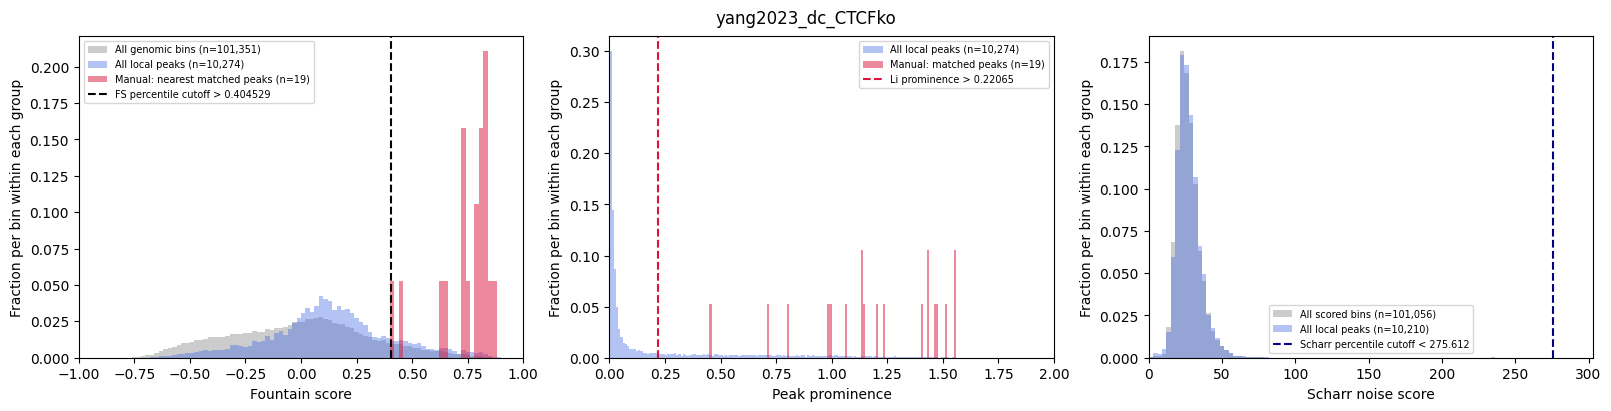

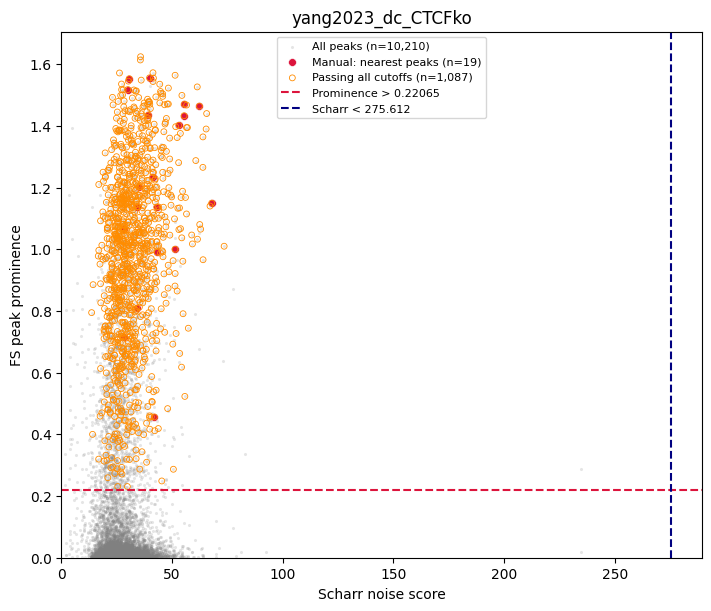

In [6]:
fig = plot_distributions(active, manual_matches)
plt.show()
fig = plot_noise_prominence(active, manual_matches)
plt.show()


## 6. Browse filtered calls in a dense grid

The saved call set includes every local peak passing this dataset's calculated cutoffs. The example grid
can additionally exclude sparse windows and space images apart. These viewing filters do not
change `active.calls` or its exported BED. Change `limit=None` to show all selected examples.


Showing 120 of 1087 passing calls


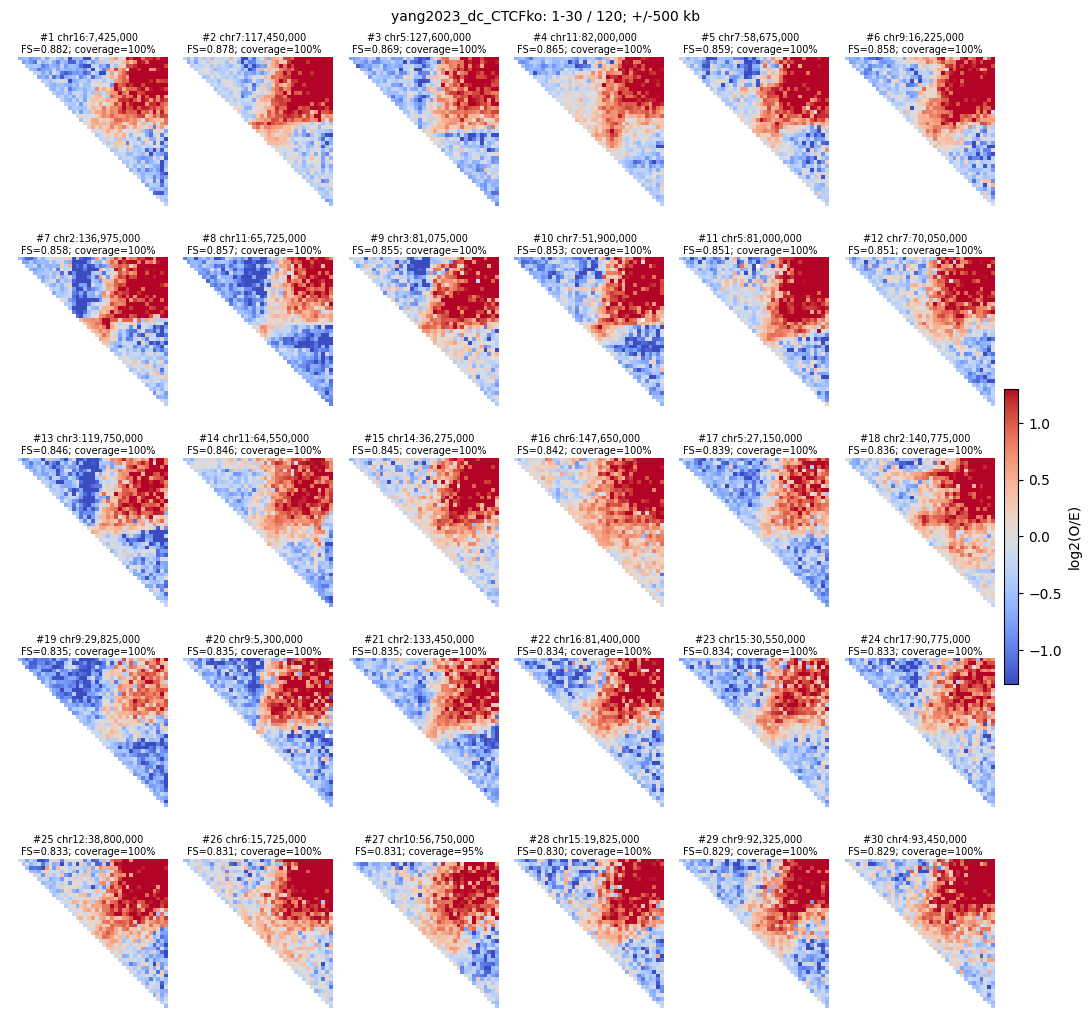

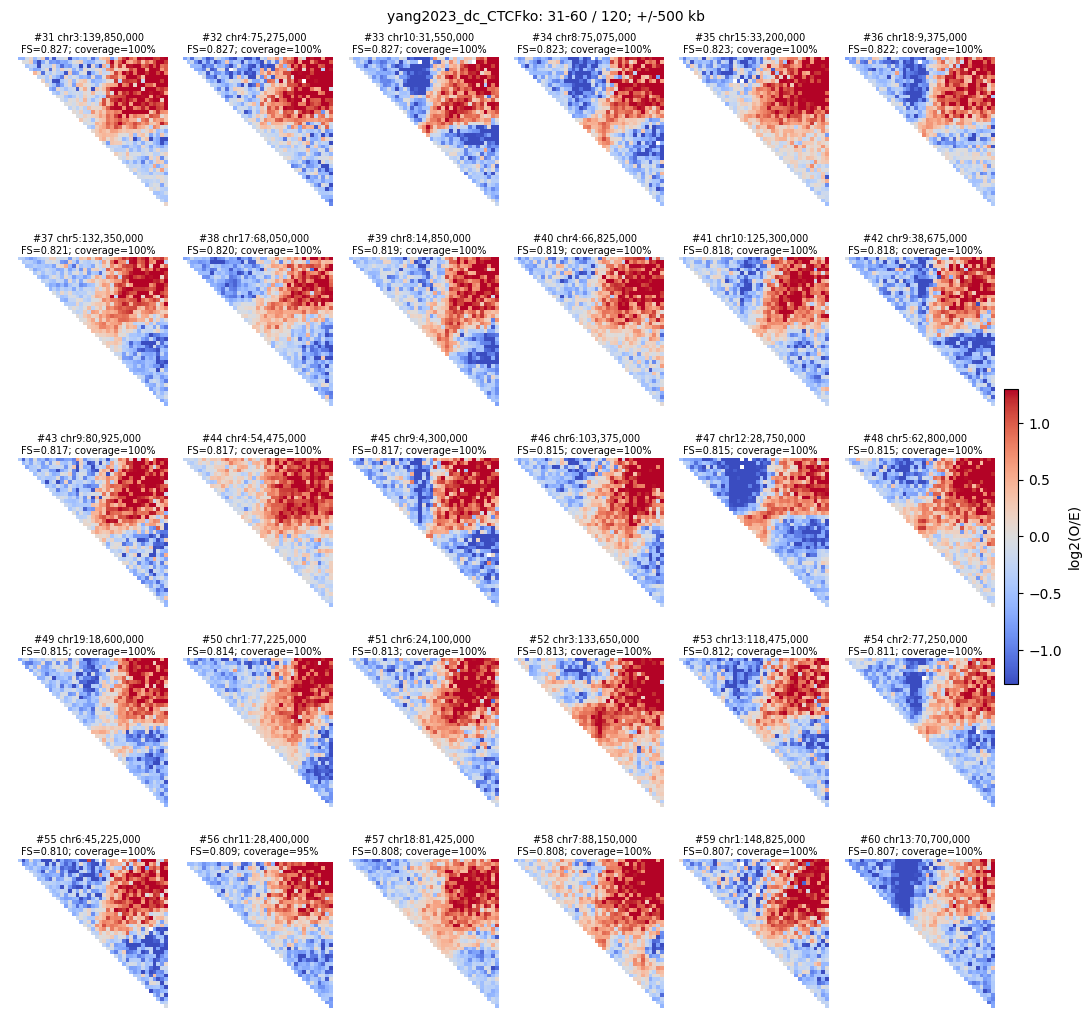

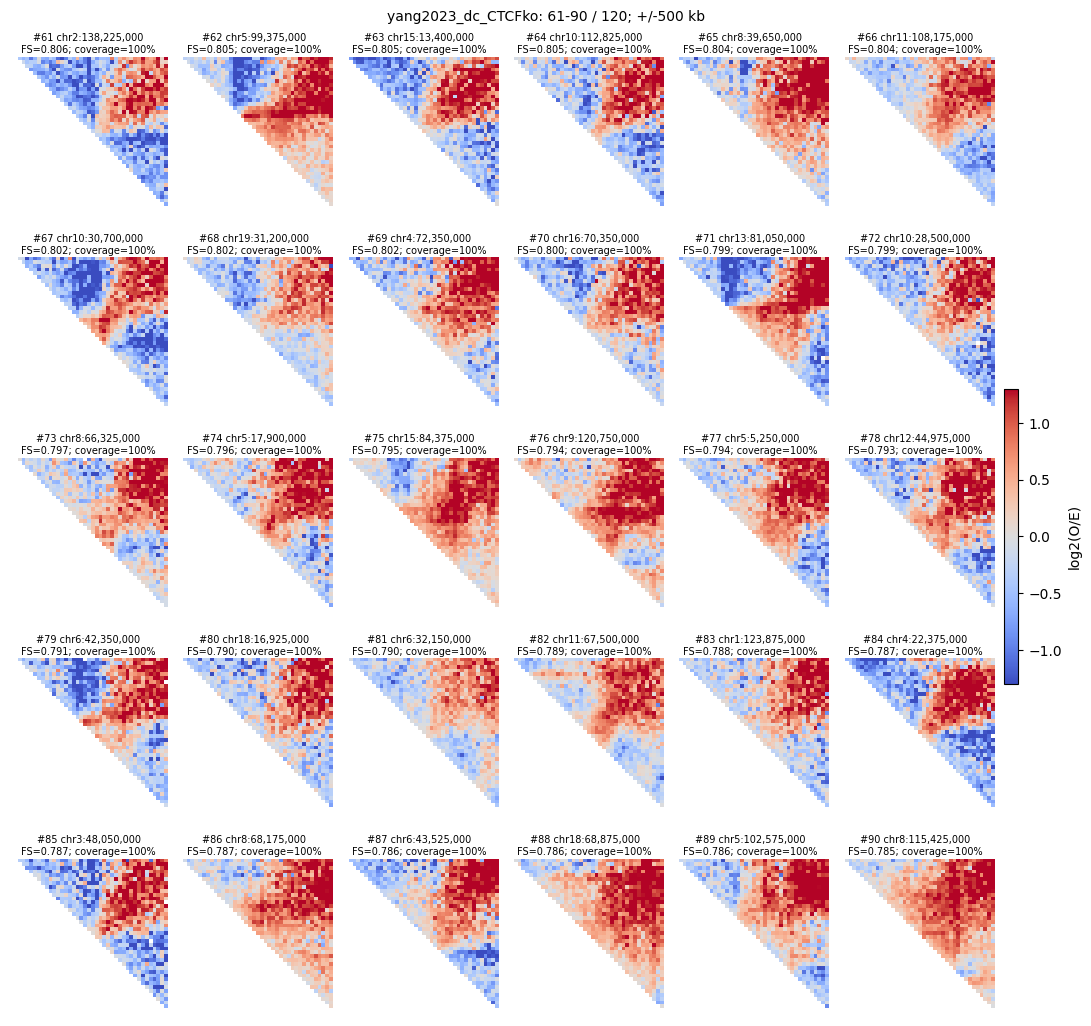

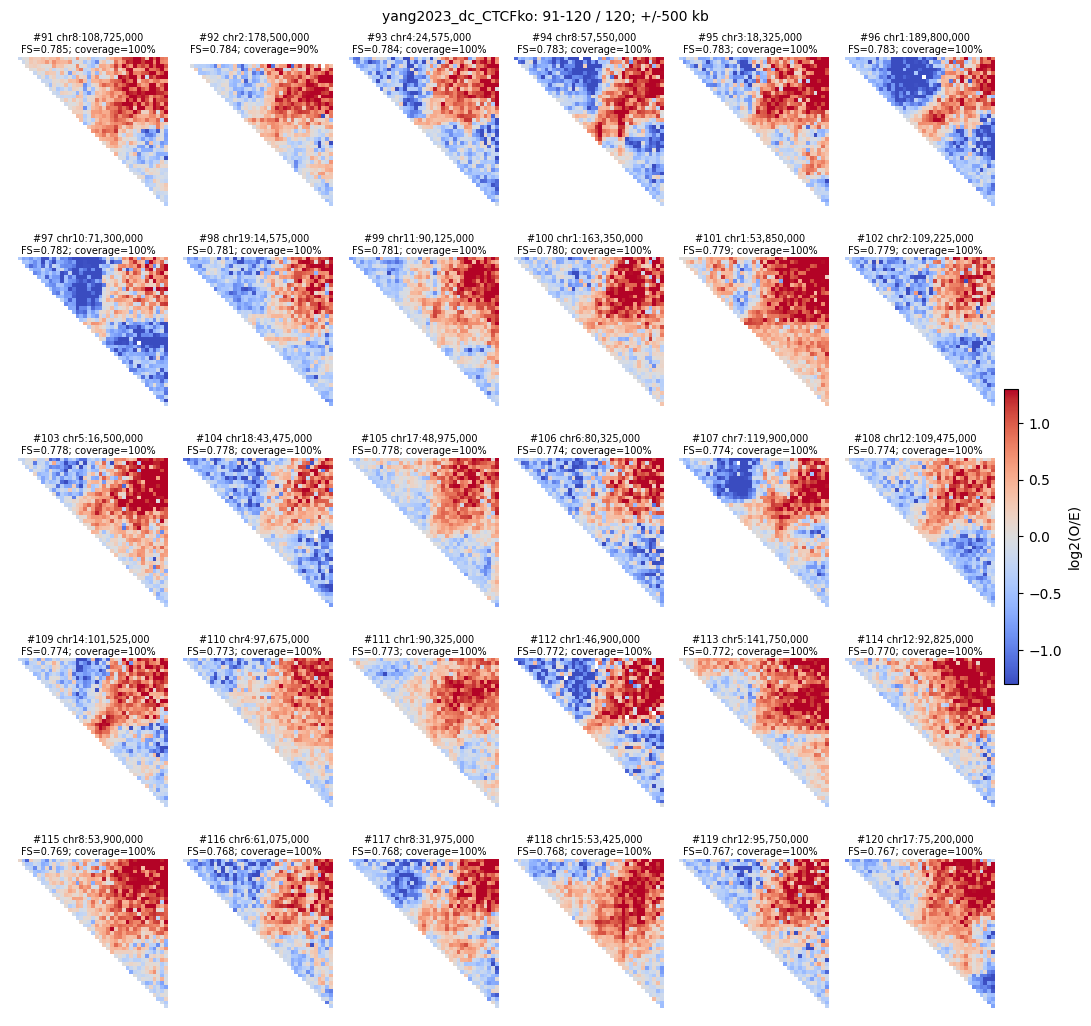

In [7]:
examples = select_examples(
    active.calls, n=120, min_separation=0,
    min_coverage=0.50, min_nonzero_fraction=0.50,
)
print(f"Showing {len(examples)} of {len(active.calls)} passing calls")
plot_dense_examples(active, examples, ncols=6, per_figure=30, panel_size=1.8, limit=None)


### Optional: independent examples away from manual windows

Use an exclusion radius of 1 Mb and 1 Mb spacing to avoid overlapping WT-mask training windows.
These are high-scoring candidates, not independently confirmed fountains.


In [8]:
RUN_OUTSIDE_MANUAL_GRID = False
if RUN_OUTSIDE_MANUAL_GRID:
    outside_examples = select_examples(
        active.calls, n=120, min_separation=1_000_000,
        manual=MANUAL_BED, exclusion_radius=1_000_000,
        min_coverage=0.5, min_nonzero_fraction=0.5,
    )
    plot_dense_examples(active, outside_examples, limit=None)


## 7. Contact map, FS, and Scharr tracks

The map displays balanced contacts; FS was calculated from O/E snippets. The rotated geometry
uses aspect 0.5. Gray/red triangles distinguish prominence below/above this dataset's Li cutoff;
orange circles mark calls passing all cutoffs. FS and Scharr panels display this dataset's
percentile thresholds. Color limits are shared display parameters.


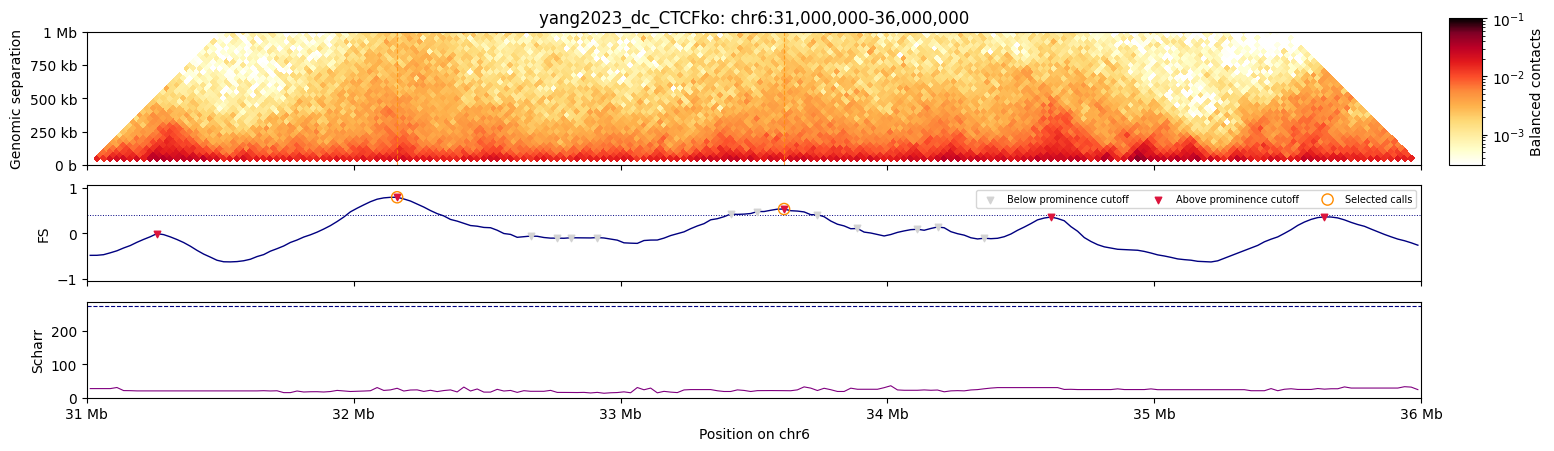

In [9]:
fig = plot_fountain_region(
    active, ("chr6", 31_000_000, 36_000_000),
    max_distance=1_000_000, vmin=0.0003, vmax=0.1,
)
plt.show()


In [10]:
RUN_MAP_EXAMPLES = False
if RUN_MAP_EXAMPLES:
    for row in active.calls.nlargest(10, "FS").itertuples(index=False):
        center = int(row.center)
        fig = plot_fountain_region(
            active, (row.chrom, center-1_500_000, center+1_500_000),
            max_distance=1_000_000,
        )
        plt.show()
        plt.close(fig)


## 8. Dataset-specific exports

`run_dataset` saves `calls.tsv` / `calls.bed` using the dataset's calculated thresholds.
Display spacing and manual exclusions do not affect these exports. Each run also stores the
WT mask identity, threshold method and full-precision values, score/expected/cache provenance,
package versions, and filter counts. `thresholds.json` records the actual estimation populations.


In [11]:
for label, result in results.items():
    print(label)
    for filename in ["scores.tsv.gz", "calls.tsv", "calls.bed", "filter_counts.tsv", "thresholds.json", "run.json"]:
        print(" ", result.directory / filename)


yang2023_dc_CTCFko
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/scores.tsv.gz
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/calls.tsv
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/calls.bed
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/filter_counts.tsv
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/thresholds.json
  /home/irzhe/chromatin_DC/scripts/fountain_pipeline/results/fountains/maps/yang2023_dc_CTCFko/run.json
